In [30]:
import pandas as pd

In [31]:
from pathlib import Path
import pandas as pd

chemin_csv = (
    Path.cwd()
    / ".."
    / ".."
    / ".."
    / ".."
    / "quantite-totale-de-produit-phytosanitaire-achetee-en-france-departement.csv"
).resolve()

print("Fichier trouvé :", chemin_csv.exists())
print("Chemin :", chemin_csv)

Fichier trouvé : True
Chemin : C:\Users\sacha\OneDrive\Bureau\2025-2026\scolaire\matières\2A\S1\projet prog\quantite-totale-de-produit-phytosanitaire-achetee-en-france-departement.csv


In [32]:
df = pd.read_csv(chemin_csv)

print("Dimensions du jeu de données :", df.shape)
print("\nNoms des colonnes :")
print(df.columns.tolist())

display(df.head())

Dimensions du jeu de données : (284746, 7)

Noms des colonnes :
['date_mesure', 'geocode_departement', 'libelle_departement', 'biocontrole', 'danger_substance', 'substance', 'valeur']


,date_mesure,geocode_departement,libelle_departement,biocontrole,danger_substance,substance,valeur
0,2017-01-01T00:00:00.000,22,Côtes-d'Armor,False,CMR2,fluoxastrobine,81.750
1,2016-01-01T00:00:00.000,03,Allier,False,CMR2,metconazole,869.591
2,2019-01-01T00:00:00.000,02,Aisne,False,Env-A,dimethenamide-p (dmta-p),9454.644
3,2018-01-01T00:00:00.000,17,Charente-Maritime,False,CMR2,cymoxanil,5011.550
4,2021-01-01T00:00:00.000,30,Gard,False,Autre,dichlorprop-p,175.220


In [33]:
# 1. Types des colonnes et mémoire utilisée
df.info()

# 2. Nombre de valeurs manquantes par colonne
print("\nValeurs manquantes :")
display(df.isna().sum().to_frame(name="valeurs_manquantes"))

# 3. Statistiques descriptives des colonnes numériques
print("\nStatistiques de la colonne valeur :")
display(df["valeur"].describe())

<class 'pandas.DataFrame'>
RangeIndex: 284746 entries, 0 to 284745
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   date_mesure          284746 non-null  str    
 1   geocode_departement  284746 non-null  str    
 2   libelle_departement  284746 non-null  str    
 3   biocontrole          284746 non-null  bool   
 4   danger_substance     284746 non-null  str    
 5   substance            284746 non-null  str    
 6   valeur               284746 non-null  float64
dtypes: bool(1), float64(1), str(5)
memory usage: 28.0 MB

Valeurs manquantes :


,valeurs_manquantes
date_mesure,0
geocode_departement,0
libelle_departement,0
biocontrole,0
danger_substance,0
substance,0
valeur,0



Statistiques de la colonne valeur :


count    2.847460e+05
mean     2.413265e+03
std      1.613555e+04
min      0.000000e+00
25%      5.500000e+00
50%      6.580300e+01
75%      5.570515e+02
max      1.253089e+06
Name: valeur, dtype: float64

In [34]:
# Convertir date_mesure en véritable date Pandas
df["date_mesure"] = pd.to_datetime(df["date_mesure"])

# Examiner les années disponibles
print("Période couverte :")
print("Première date :", df["date_mesure"].min())
print("Dernière date :", df["date_mesure"].max())
print("\nNombre de lignes par année :")
display(df["date_mesure"].dt.year.value_counts().sort_index())

# Vérifier les valeurs négatives et les zéros
print("\nValeurs négatives :", (df["valeur"] < 0).sum())
print("Valeurs nulles :", (df["valeur"] == 0).sum())

# Examiner les 10 valeurs les plus élevées
print("\nLes 10 valeurs les plus élevées :")
display(
    df.nlargest(10, "valeur")[
        ["date_mesure", "geocode_departement",
         "libelle_departement", "substance", "valeur"]
    ]
)

Période couverte :
Première date : 2013-01-01 00:00:00
Dernière date : 2023-01-01 00:00:00

Nombre de lignes par année :


date_mesure
2013    22949
2014    27126
2015    26963
2016    26937
2017    26998
2018    27263
2019    26469
2020    26056
2021    25330
2022    24499
2023    24156
Name: count, dtype: int64


Valeurs négatives : 0
Valeurs nulles : 751

Les 10 valeurs les plus élevées :


,date_mesure,geocode_departement,libelle_departement,substance,valeur
242809,2020-01-01,33,Gironde,soufre pour pulverisation (micronise),1253089.338
248687,2022-01-01,33,Gironde,soufre pour pulverisation (micronise),1214731.130
259517,2021-01-01,33,Gironde,soufre pour pulverisation (micronise),1192914.600
247342,2018-01-01,33,Gironde,soufre pour pulverisation (micronise),1125810.890
233215,2023-01-01,33,Gironde,soufre pour pulverisation (micronise),1107004.980
151767,2014-01-01,44,Loire-Atlantique,metam-sodium,1045904.940
170544,2019-01-01,33,Gironde,soufre pour pulverisation (micronise),1008815.140
206753,2017-01-01,33,Gironde,soufre pour pulverisation (micronise),981036.500
251378,2016-01-01,33,Gironde,soufre pour pulverisation (micronise),939298.697
143567,2014-01-01,33,Gironde,soufre pour pulverisation (micronise),759445.672


In [35]:
# 1. Nombre de départements et liste des codes
print("Nombre de codes départementaux :",
      df["geocode_departement"].nunique())

print("\nCodes départementaux :")
print(sorted(df["geocode_departement"].unique()))

# 2. Vérifier les substances
print("\nNombre de substances différentes :",
      df["substance"].nunique())

# 3. Vérifier les catégories de danger
print("\nRépartition des catégories de danger :")
display(df["danger_substance"].value_counts())

# 4. Vérifier les modalités du biocontrôle
print("\nRépartition du biocontrôle :")
display(df["biocontrole"].value_counts())

Nombre de codes départementaux : 101

Codes départementaux :
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '21', '22', '23', '24', '25', '26', '27', '28', '29', '2A', '2B', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '971', '972', '973', '974', '976']

Nombre de substances différentes : 511

Répartition des catégories de danger :


danger_substance
Env-A      114160
CMR2        72516
Autre       49323
Sante-A     26090
Env-B       11706
CMR1        10951
Name: count, dtype: int64


Répartition du biocontrôle :


biocontrole
False    239590
True      45156
Name: count, dtype: int64

In [36]:
# 1. Extraire l'année
df["annee"] = df["date_mesure"].dt.year

# 2. Vérifier les départements présents par année
print("Nombre de départements par année :")
display(
    df.groupby("annee")["geocode_departement"]
      .nunique()
      .rename("nombre_departements")
)

# 3. Rechercher les doublons exacts sur les variables disponibles
colonnes_observation = [
    "date_mesure",
    "geocode_departement",
    "biocontrole",
    "danger_substance",
    "substance"
]

print(
    "Doublons sur les variables descriptives :",
    df.duplicated(subset=colonnes_observation).sum()
)

# 4. Afficher quelques lignes concernant les départements d'outre-mer
codes_outre_mer = ["971", "972", "973", "974", "976"]

display(
    df[df["geocode_departement"].isin(codes_outre_mer)]
      .head(10)
)

Nombre de départements par année :


annee
2013    101
2014    101
2015    101
2016    101
2017    101
2018    101
2019    101
2020    101
2021    101
2022    101
2023    101
Name: nombre_departements, dtype: int64

Doublons sur les variables descriptives : 0


,date_mesure,geocode_departement,libelle_departement,biocontrole,danger_substance,substance,valeur,annee
382,2023-01-01,971,Guadeloupe,False,Autre,clopyralid (sous forme de sel de monoethanolam...,0.350,2023
562,2020-01-01,973,Guyane,False,CMR2,phosmet,30.000,2020
585,2023-01-01,971,Guadeloupe,False,CMR2,spiroxamine,0.440,2023
1594,2015-01-01,974,La Réunion,False,Env-A,glyphosate,40101.957,2015
1809,2014-01-01,972,Martinique,False,Env-A,s-metolachlore,9.600,2014
1965,2015-01-01,973,Guyane,False,Env-A,chlorantraniliprole,3.000,2015
2333,2018-01-01,971,Guadeloupe,False,Env-A,acibenzolar-s-methyl,0.600,2018
2754,2016-01-01,972,Martinique,False,Sante-A,deltamethrine,0.300,2016
3702,2022-01-01,972,Martinique,False,Autre,flonicamide,10.000,2022
5027,2014-01-01,976,Mayotte,False,Autre,fosetyl-aluminium,16.956,2014


In [37]:
# 1. Examiner les modalités des variables catégorielles
print("Catégories de danger :")
print(sorted(df["danger_substance"].unique()))

print("\nModalités du biocontrôle :")
print(sorted(df["biocontrole"].unique()))

# 2. Examiner les départements métropolitains et ultramarins
codes = sorted(df["geocode_departement"].unique())

codes_outre_mer = {"971", "972", "973", "974", "976"}
codes_metropole = [c for c in codes if c not in codes_outre_mer]

print("\nNombre de codes hors outre-mer :", len(codes_metropole))
print("Codes hors outre-mer :", codes_metropole)

# 3. Vérifier si une substance apparaît plusieurs fois
# dans un même département et une même année
nb_lignes_par_groupe = df.groupby(
    ["geocode_departement", "annee", "substance"]
).size()

print(
    "\nGroupes département-année-substance avec plusieurs lignes :",
    (nb_lignes_par_groupe > 1).sum()
)

display(nb_lignes_par_groupe[nb_lignes_par_groupe > 1].head(10))

Catégories de danger :
['Autre', 'CMR1', 'CMR2', 'Env-A', 'Env-B', 'Sante-A']

Modalités du biocontrôle :
[np.False_, np.True_]

Nombre de codes hors outre-mer : 96
Codes hors outre-mer : ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '21', '22', '23', '24', '25', '26', '27', '28', '29', '2A', '2B', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95']

Groupes département-année-substance avec plusieurs lignes : 8219


geocode_departement  annee  substance             
01                   2013   pyrethrines               2
                     2014   acide pelargonique        2
                            butoxyde de piperonyle    2
                            pyrethrines               2
                            soufre                    2
                            soufre triture            2
                            soufre triture ventile    2
                     2015   abamectine                2
                            acide pelargonique        2
                            butoxyde de piperonyle    2
dtype: int64

In [38]:
# Pour chaque département, année et substance,
# compter les lignes et les modalités des deux variables
analyse_doublons = (
    df.groupby(["geocode_departement", "annee", "substance"])
      .agg(
          nb_lignes=("valeur", "size"),
          nb_biocontrole=("biocontrole", "nunique"),
          nb_categories_danger=("danger_substance", "nunique")
      )
)

# Garder uniquement les groupes ayant plusieurs lignes
groupes_multiples = analyse_doublons[
    analyse_doublons["nb_lignes"] > 1
]

print("Groupes ayant plusieurs lignes :", len(groupes_multiples))
print(
    "Groupes où biocontrole varie :",
    (groupes_multiples["nb_biocontrole"] > 1).sum()
)
print(
    "Groupes où la catégorie de danger varie :",
    (groupes_multiples["nb_categories_danger"] > 1).sum()
)

display(groupes_multiples.head(15))

Groupes ayant plusieurs lignes : 8219
Groupes où biocontrole varie : 8219
Groupes où la catégorie de danger varie : 0


nb_lignes  \
geocode_departement annee substance                                     
01                  2013  pyrethrines                               2   
                    2014  acide pelargonique                        2   
                          butoxyde de piperonyle                    2   
                          pyrethrines                               2   
                          soufre                                    2   
                          soufre triture                            2   
                          soufre triture ventile                    2   
                    2015  abamectine                                2   
                          acide pelargonique                        2   
                          butoxyde de piperonyle                    2   
                          fer sous forme de sulfate de fer          2   
                          pyrethrines                               2   
                          soufre                                    2   
                          soufre triture ventile                    2   
                    2016  abamectine                                2   

                                                            nb_biocontrole  \
geocode_departement annee substance                                          
01                  2013  pyrethrines                                    2   
                    2014  acide pelargonique                             2   
                          butoxyde de piperonyle                         2   
                          pyrethrines                                    2   
                          soufre                                         2   
                          soufre triture                                 2   
                          soufre triture ventile                         2   
                    2015  abamectine                                     2   
                          acide pelargonique                             2   
                          butoxyde de piperonyle                         2   
                          fer sous forme de sulfate de fer               2   
                          pyrethrines                                    2   
                          soufre                                         2   
                          soufre triture ventile                         2   
                    2016  abamectine                                     2   

                                                            nb_categories_danger  
geocode_departement annee substance                                               
01                  2013  pyrethrines                                          1  
                    2014  acide pelargonique                                   1  
                          butoxyde de piperonyle                               1  
                          pyrethrines                                          1  
                          soufre                                               1  
                          soufre triture                                       1  
                          soufre triture ventile                               1  
                    2015  abamectine                                           1  
                          acide pelargonique                                   1  
                          butoxyde de piperonyle                               1  
                          fer sous forme de sulfate de fer                     1  
                          pyrethrines                                          1  
                          soufre                                               1  
                          soufre triture ventile                               1  
                    2016  abamectine                                           1

In [39]:
display(
    df[
        (df["geocode_departement"] == "01")
        & (df["annee"] == 2013)
        & (df["substance"] == "pyrethrines")
    ][
        [
            "date_mesure",
            "geocode_departement",
            "annee",
            "substance",
            "biocontrole",
            "danger_substance",
            "valeur"
        ]
    ]
)

,date_mesure,geocode_departement,annee,substance,biocontrole,danger_substance,valeur
54728,2013-01-01,01,2013,pyrethrines,True,Env-A,0.014
55434,2013-01-01,01,2013,pyrethrines,False,Env-A,1.000


In [40]:
# Conserver toutes les années pour l'exploration
df_agrege = (
    df.groupby(
        [
            "geocode_departement",
            "libelle_departement",
            "annee",
            "substance",
            "danger_substance"
        ],
        as_index=False
    )
    .agg(
        quantite_totale=("valeur", "sum")
    )
)

print("Période :", df_agrege["annee"].min(),
      "à", df_agrege["annee"].max())
print("Dimensions avant agrégation :", df.shape)
print("Dimensions après agrégation :", df_agrege.shape)

display(df_agrege.head())

Période : 2013 à 2023
Dimensions avant agrégation : (284746, 8)
Dimensions après agrégation : (276527, 6)


,geocode_departement,libelle_departement,annee,substance,danger_substance,quantite_totale
0,01,Ain,2013,"2,4-d",Env-B,2324.955
1,01,Ain,2013,"2,4-db",Env-A,48.000
2,01,Ain,2013,"2,4-mcpa",Env-A,1567.139
3,01,Ain,2013,"2,4-mcpb",Env-A,98.000
4,01,Ain,2013,abamectine,CMR2,0.954


In [41]:
# Vérifier l'unicité des combinaisons après agrégation
cles = [
    "geocode_departement",
    "annee",
    "substance",
    "danger_substance"
]

print("Nombre de doublons restants :", df_agrege.duplicated(subset=cles).sum())

print("\nNombre de lignes :", len(df_agrege))
print("Nombre de départements :", df_agrege["geocode_departement"].nunique())
print("Nombre d'années :", df_agrege["annee"].nunique())
print("Nombre de substances :", df_agrege["substance"].nunique())

print("\nValeurs manquantes :")
display(df_agrege.isna().sum().to_frame(name="valeurs_manquantes"))

Nombre de doublons restants : 0

Nombre de lignes : 276527
Nombre de départements : 101
Nombre d'années : 11
Nombre de substances : 511

Valeurs manquantes :


,valeurs_manquantes
geocode_departement,0
libelle_departement,0
annee,0
substance,0
danger_substance,0
quantite_totale,0


In [42]:
# Somme des quantités par département sur toute la période
quantites_departements = (
    df_agrege.groupby(
        ["geocode_departement", "libelle_departement"],
        as_index=False
    )
    .agg(quantite_totale=("quantite_totale", "sum"))
    .sort_values("quantite_totale", ascending=False)
)

# Afficher les 10 premiers départements
display(quantites_departements.head(10))

,geocode_departement,libelle_departement,quantite_totale
33,33,Gironde,3.559959e+07
51,51,Marne,2.837628e+07
80,80,Somme,2.219912e+07
62,62,Pas-de-Calais,1.994494e+07
34,34,Hérault,1.945978e+07
30,30,Gard,1.868922e+07
16,17,Charente-Maritime,1.841409e+07
26,28,Eure-et-Loir,1.683140e+07
1,02,Aisne,1.639015e+07
84,84,Vaucluse,1.633070e+07


In [43]:
import geopandas as gpd
import matplotlib.pyplot as plt

url_geojson = (
    "https://raw.githubusercontent.com/"
    "gregoiredavid/france-geojson/master/departements.geojson"
)

departements = gpd.read_file(url_geojson)

print("Nombre de départements :", len(departements))
print("Colonnes :", departements.columns.tolist())

departements.head()

Nombre de départements : 96
Colonnes : ['code', 'nom', 'geometry']


,code,nom,geometry
0,01,Ain,"POLYGON ((4.78021 46.17668, 4.78024 46.18905, ..."
1,02,Aisne,"POLYGON ((3.17296 50.01131, 3.17382 50.01186, ..."
2,03,Allier,"POLYGON ((3.03207 46.79491, 3.03424 46.7908, 3..."
3,04,Alpes-de-Haute-Provence,"POLYGON ((5.67604 44.19143, 5.67817 44.19051, ..."
4,05,Hautes-Alpes,"POLYGON ((6.26057 45.12685, 6.26417 45.12641, ..."


In [44]:
# Préparer les codes pour la jointure
quantites_departements["code"] = (
    quantites_departements["geocode_departement"].astype(str).str.zfill(2)
)

departements["code"] = departements["code"].astype(str).str.zfill(2)

# Associer les quantités aux contours géographiques
carte = departements.merge(
    quantites_departements[["code", "quantite_totale"]],
    on="code",
    how="left"
)

print("Nombre de départements :", len(carte))
print("Départements sans quantité :", carte["quantite_totale"].isna().sum())

Nombre de départements : 96
Départements sans quantité : 0


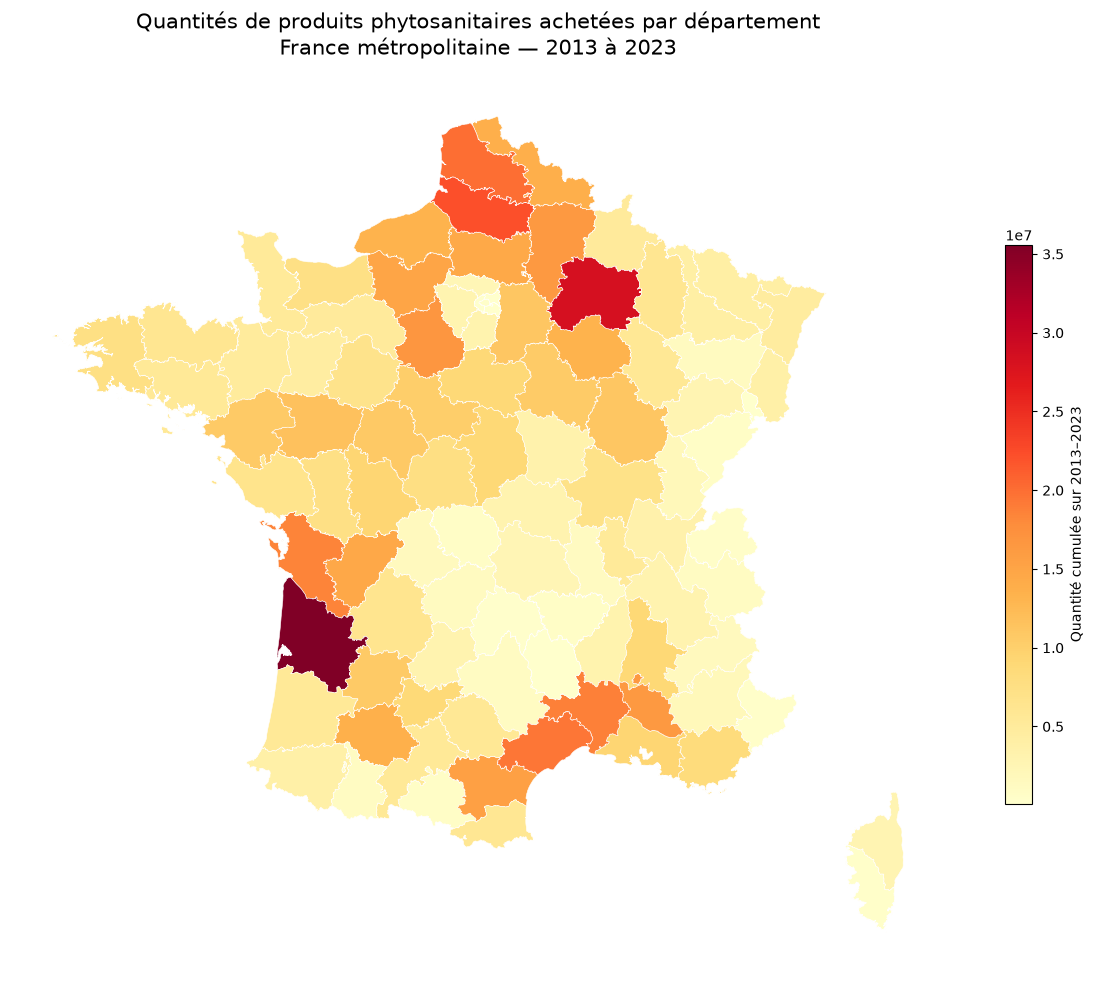

In [45]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

carte.plot(
    column="quantite_totale",
    cmap="YlOrRd",
    linewidth=0.4,
    edgecolor="white",
    legend=True,
    ax=ax,
    legend_kwds={
        "label": "Quantité cumulée sur 2013–2023",
        "shrink": 0.6
    }
)

ax.set_title(
    "Quantités de produits phytosanitaires achetées par département\n"
    "France métropolitaine — 2013 à 2023",
    fontsize=15,
    pad=15
)

ax.axis("off")
plt.tight_layout()
plt.show()

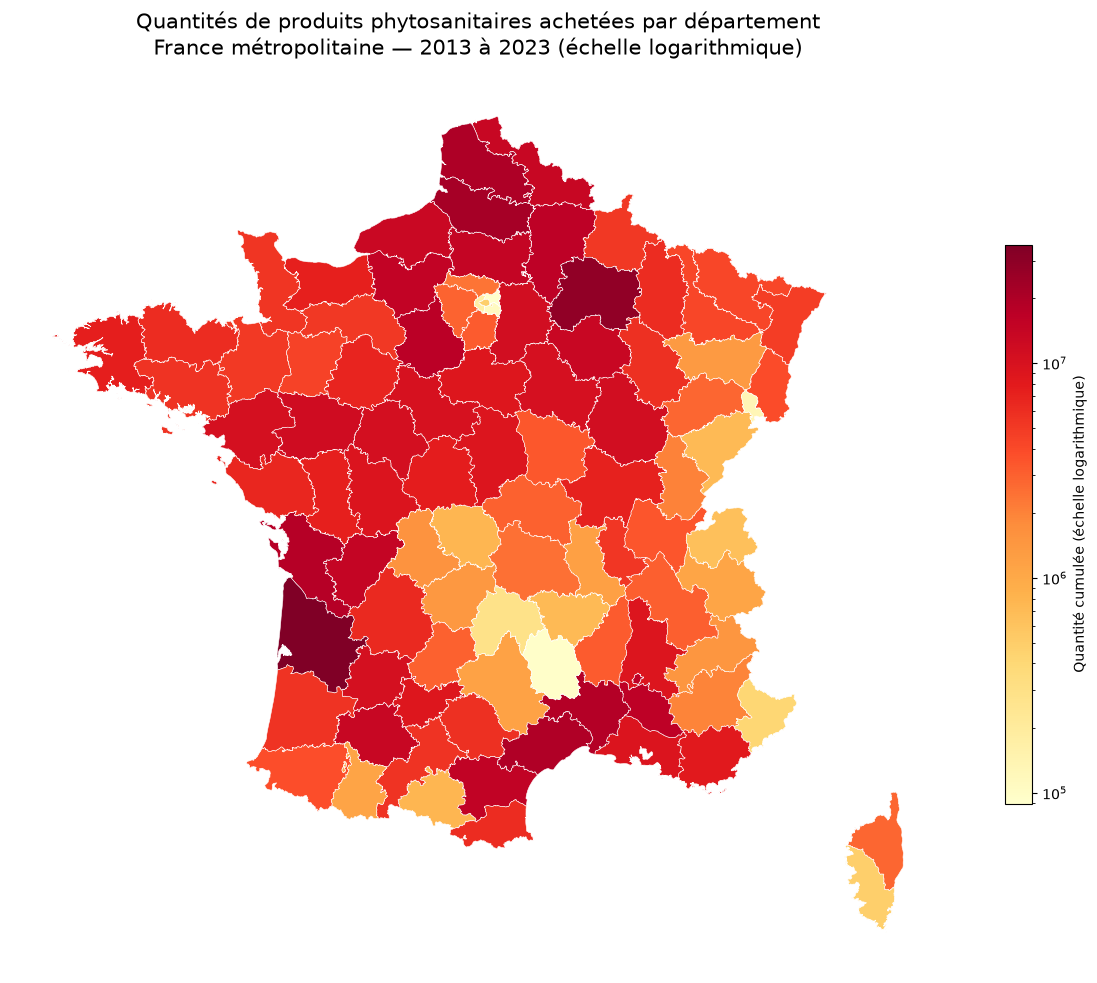

In [46]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

fig, ax = plt.subplots(figsize=(12, 10))

carte.plot(
    column="quantite_totale",
    cmap="YlOrRd",
    norm=LogNorm(
        vmin=carte.loc[carte["quantite_totale"] > 0, "quantite_totale"].min(),
        vmax=carte["quantite_totale"].max()
    ),
    linewidth=0.4,
    edgecolor="white",
    legend=True,
    ax=ax,
    legend_kwds={
        "label": "Quantité cumulée (échelle logarithmique)",
        "shrink": 0.6
    }
)

ax.set_title(
    "Quantités de produits phytosanitaires achetées par département\n"
    "France métropolitaine — 2013 à 2023 (échelle logarithmique)",
    fontsize=15,
    pad=15
)

ax.axis("off")
plt.tight_layout()
plt.show()


In [47]:
quantites_annuelles = (
    df_agrege
    .groupby("annee", as_index=False)
    .agg(quantite_totale=("quantite_totale", "sum"))
    .sort_values("annee")
)

display(quantites_annuelles)

,annee,quantite_totale
0,2013,2.420617e+07
1,2014,7.075761e+07
2,2015,6.328711e+07
3,2016,6.836063e+07
4,2017,6.695959e+07
5,2018,8.132505e+07
6,2019,5.240073e+07
7,2020,6.260389e+07
8,2021,6.730963e+07
9,2022,6.618906e+07


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    quantites_annuelles["annee"],
    quantites_annuelles["quantite_totale"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Évolution annuelle des achats de produits phytosanitaires (2013–2023)"
)
ax.set_xlabel("Année")
ax.set_ylabel("Quantité totale (en millions d'unités de valeur)")

# Afficher l'axe vertical en millions
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x / 1e6:.1f}")
)

ax.set_xticks(quantites_annuelles["annee"])
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [53]:
import random

substances_selectionnees = random.sample(
    df_agrege["substance"].dropna().unique().tolist(),
    10
)

df_substances = df_agrege[
    df_agrege["substance"].isin(substances_selectionnees)
].copy()

print(substances_selectionnees)

['fenpicoxamide', 'bentazone', 'phosphure de calcium', 'foramsulfuron', 'flutriafol', 'bifenazate', 'phlebiopsis gigantea souche vra 1835', "cuivre de l'oxyde cuivreux", 'nicosulfuron', 'oxydemeton-methyl']


In [54]:
import pandas as pd
import matplotlib.pyplot as plt

df_evolution = (
    df_substances
    .groupby(["annee", "substance"], as_index=False)["quantite_totale"]
    .sum()
)

df_evolution.head()

,annee,substance,quantite_totale
0,2013,bentazone,73206.688
1,2013,bifenazate,99.070
2,2013,cuivre de l'oxyde cuivreux,85497.464
3,2013,flutriafol,738.630
4,2013,foramsulfuron,755.892


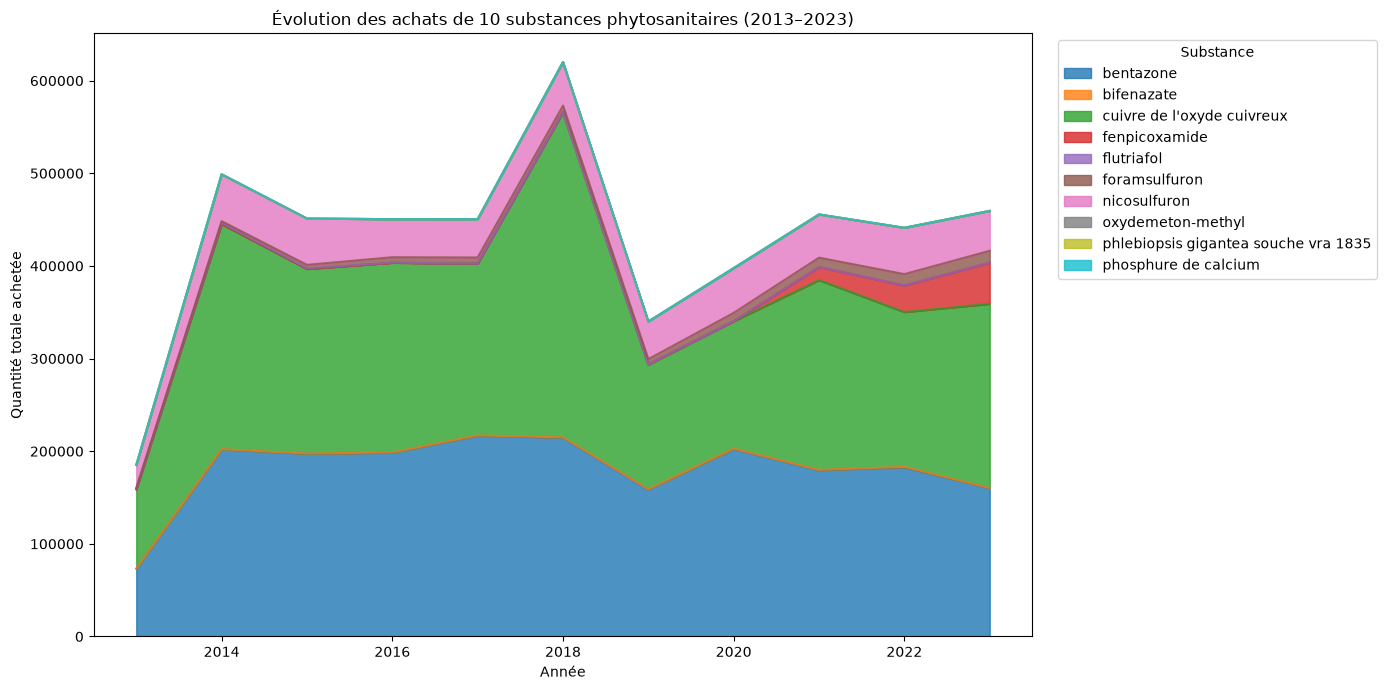

In [55]:
df_pivot = (
    df_evolution
    .pivot(index="annee", columns="substance", values="quantite_totale")
    .fillna(0)
)

df_pivot.plot(
    kind="area",
    stacked=True,
    figsize=(14, 7),
    alpha=0.8
)

plt.title("Évolution des achats de 10 substances phytosanitaires (2013–2023)")
plt.xlabel("Année")
plt.ylabel("Quantité totale achetée")
plt.legend(title="Substance", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

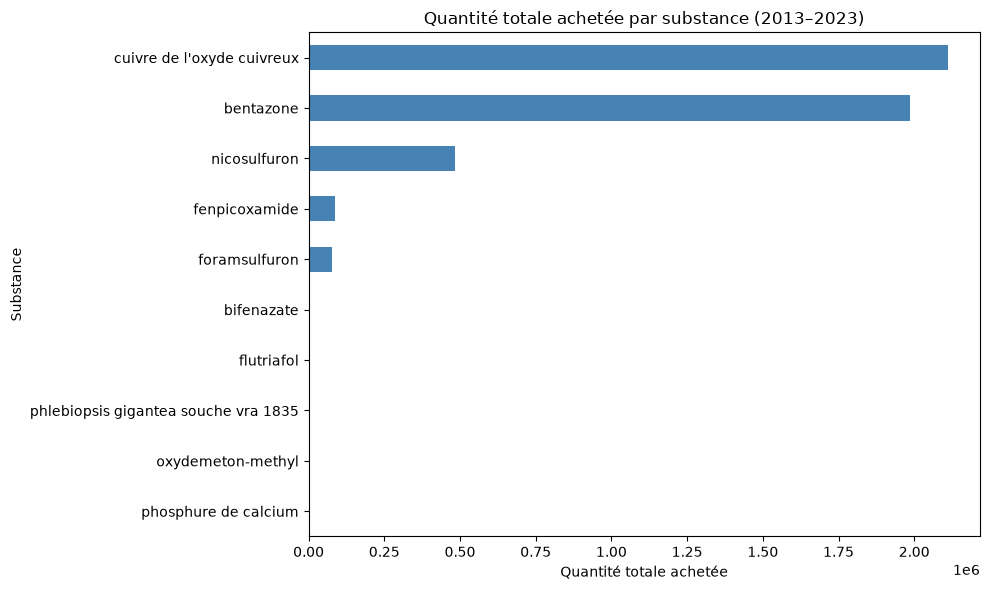

In [56]:
quantites_substances = (
    df_substances
    .groupby("substance")["quantite_totale"]
    .sum()
    .sort_values()
)

plt.figure(figsize=(10, 6))

quantites_substances.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Quantité totale achetée par substance (2013–2023)")
plt.xlabel("Quantité totale achetée")
plt.ylabel("Substance")
plt.tight_layout()
plt.show()

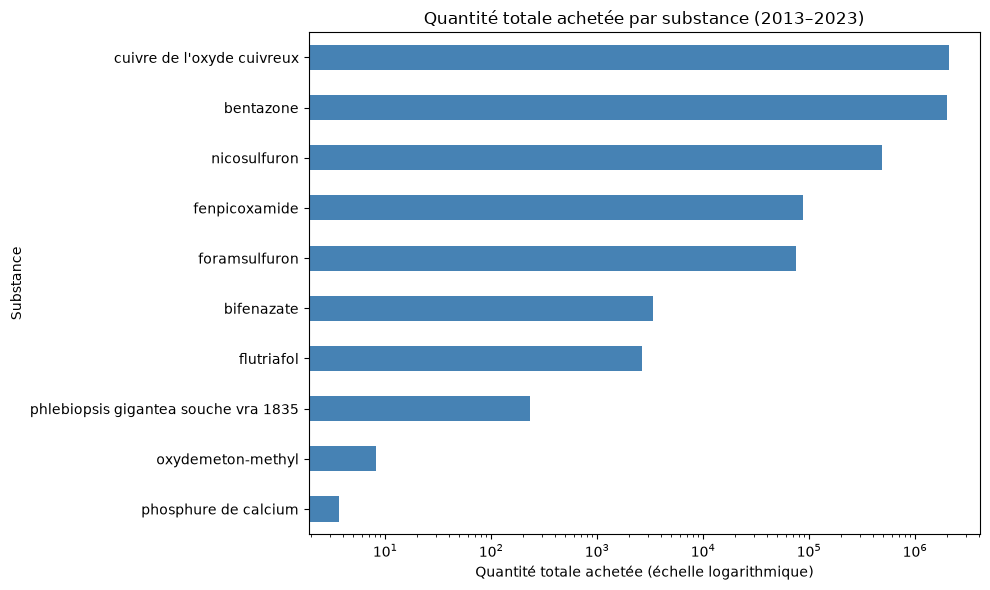

In [57]:
quantites_substances = (
    df_substances
    .groupby("substance")["quantite_totale"]
    .sum()
    .sort_values()
)

plt.figure(figsize=(10, 6))

quantites_substances.plot(
    kind="barh",
    color="steelblue",
    logx=True
)

plt.title("Quantité totale achetée par substance (2013–2023)")
plt.xlabel("Quantité totale achetée (échelle logarithmique)")
plt.ylabel("Substance")
plt.tight_layout()
plt.show()

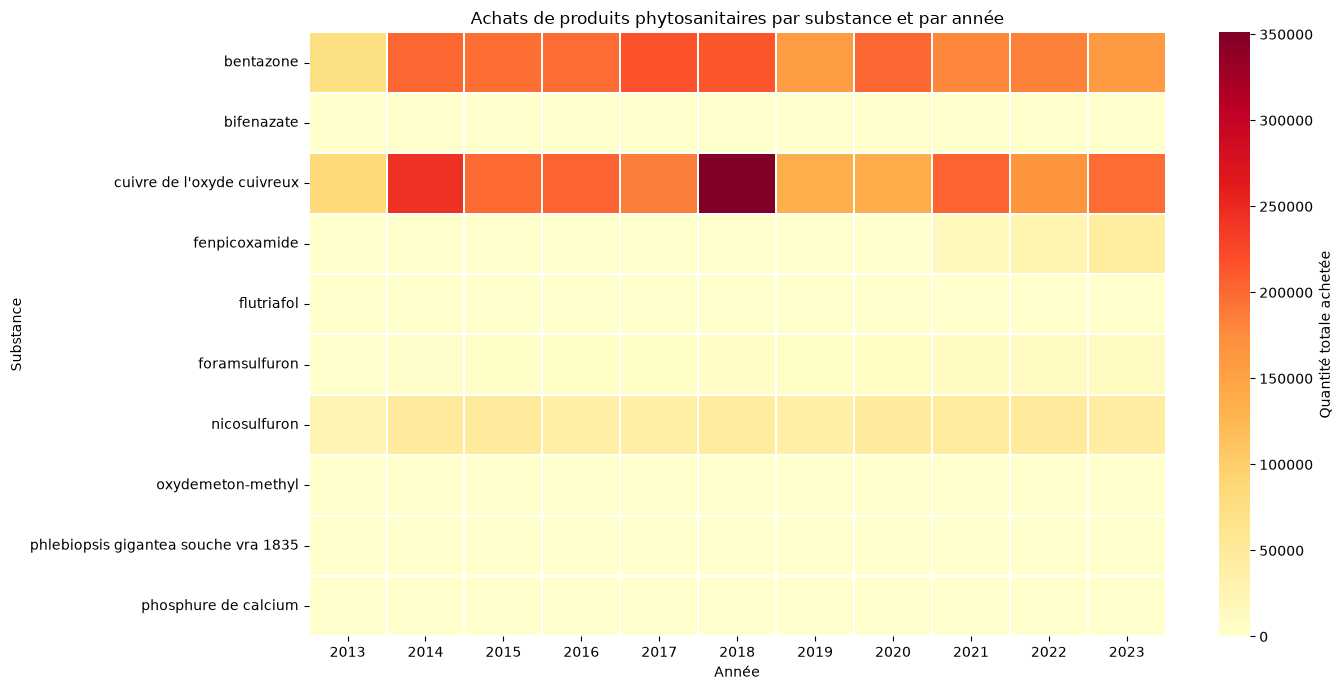

In [58]:
import seaborn as sns

df_heatmap = (
    df_evolution
    .pivot(index="substance", columns="annee", values="quantite_totale")
    .fillna(0)
)

plt.figure(figsize=(14, 7))

sns.heatmap(
    df_heatmap,
    cmap="YlOrRd",
    linewidths=0.3,
    cbar_kws={"label": "Quantité totale achetée"}
)

plt.title("Achats de produits phytosanitaires par substance et par année")
plt.xlabel("Année")
plt.ylabel("Substance")
plt.tight_layout()
plt.show()

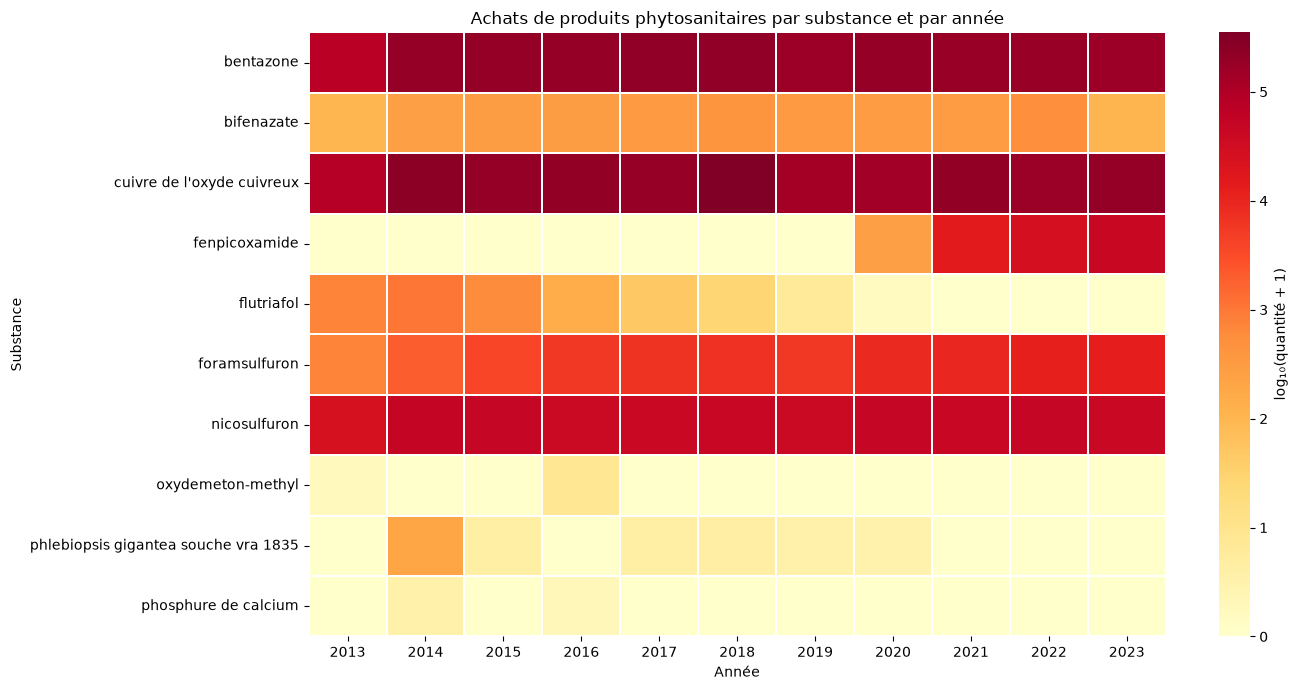

In [59]:
import numpy as np
import seaborn as sns

df_heatmap = (
    df_evolution
    .pivot(index="substance", columns="annee", values="quantite_totale")
    .fillna(0)
)

plt.figure(figsize=(14, 7))

sns.heatmap(
    np.log10(df_heatmap + 1),
    cmap="YlOrRd",
    linewidths=0.3,
    cbar_kws={"label": "log₁₀(quantité + 1)"}
)

plt.title("Achats de produits phytosanitaires par substance et par année")
plt.xlabel("Année")
plt.ylabel("Substance")
plt.tight_layout()
plt.show()

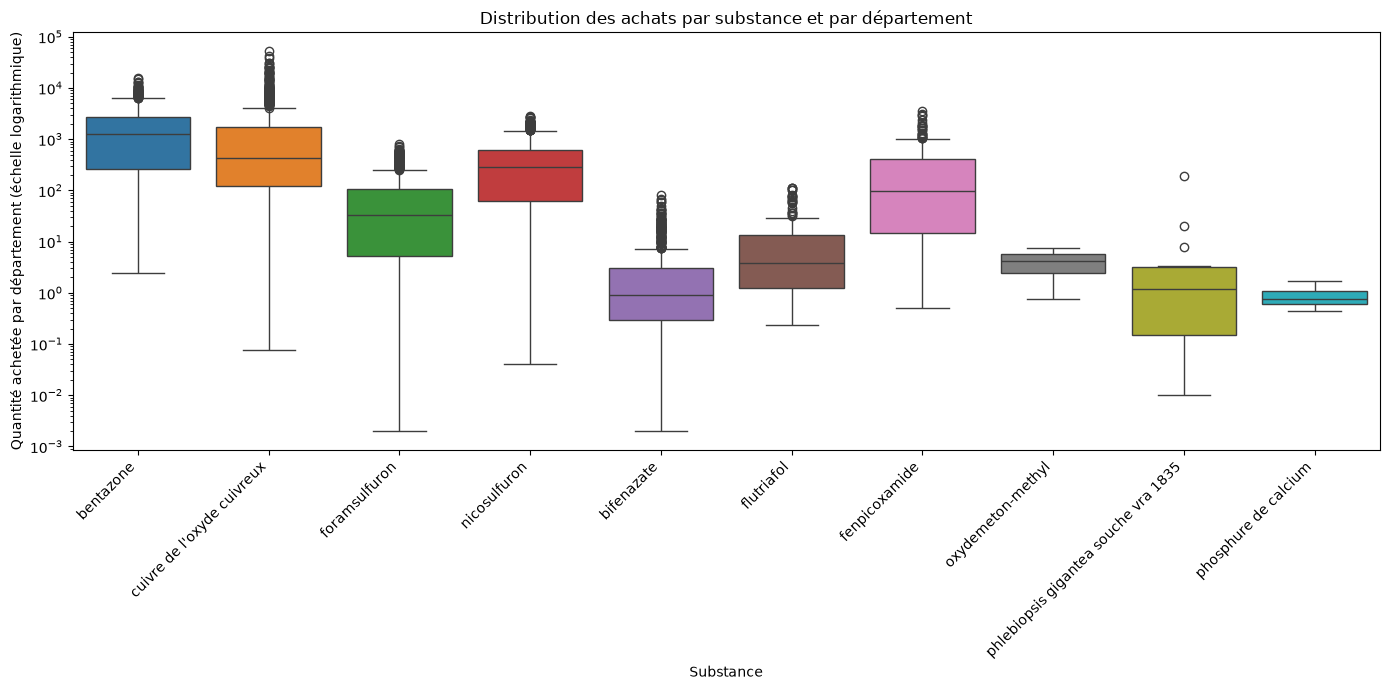

In [60]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df_substances,
    x="substance",
    y="quantite_totale",
    hue="substance",
    legend=False
)

plt.yscale("log")
plt.title("Distribution des achats par substance et par département")
plt.xlabel("Substance")
plt.ylabel("Quantité achetée par département (échelle logarithmique)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

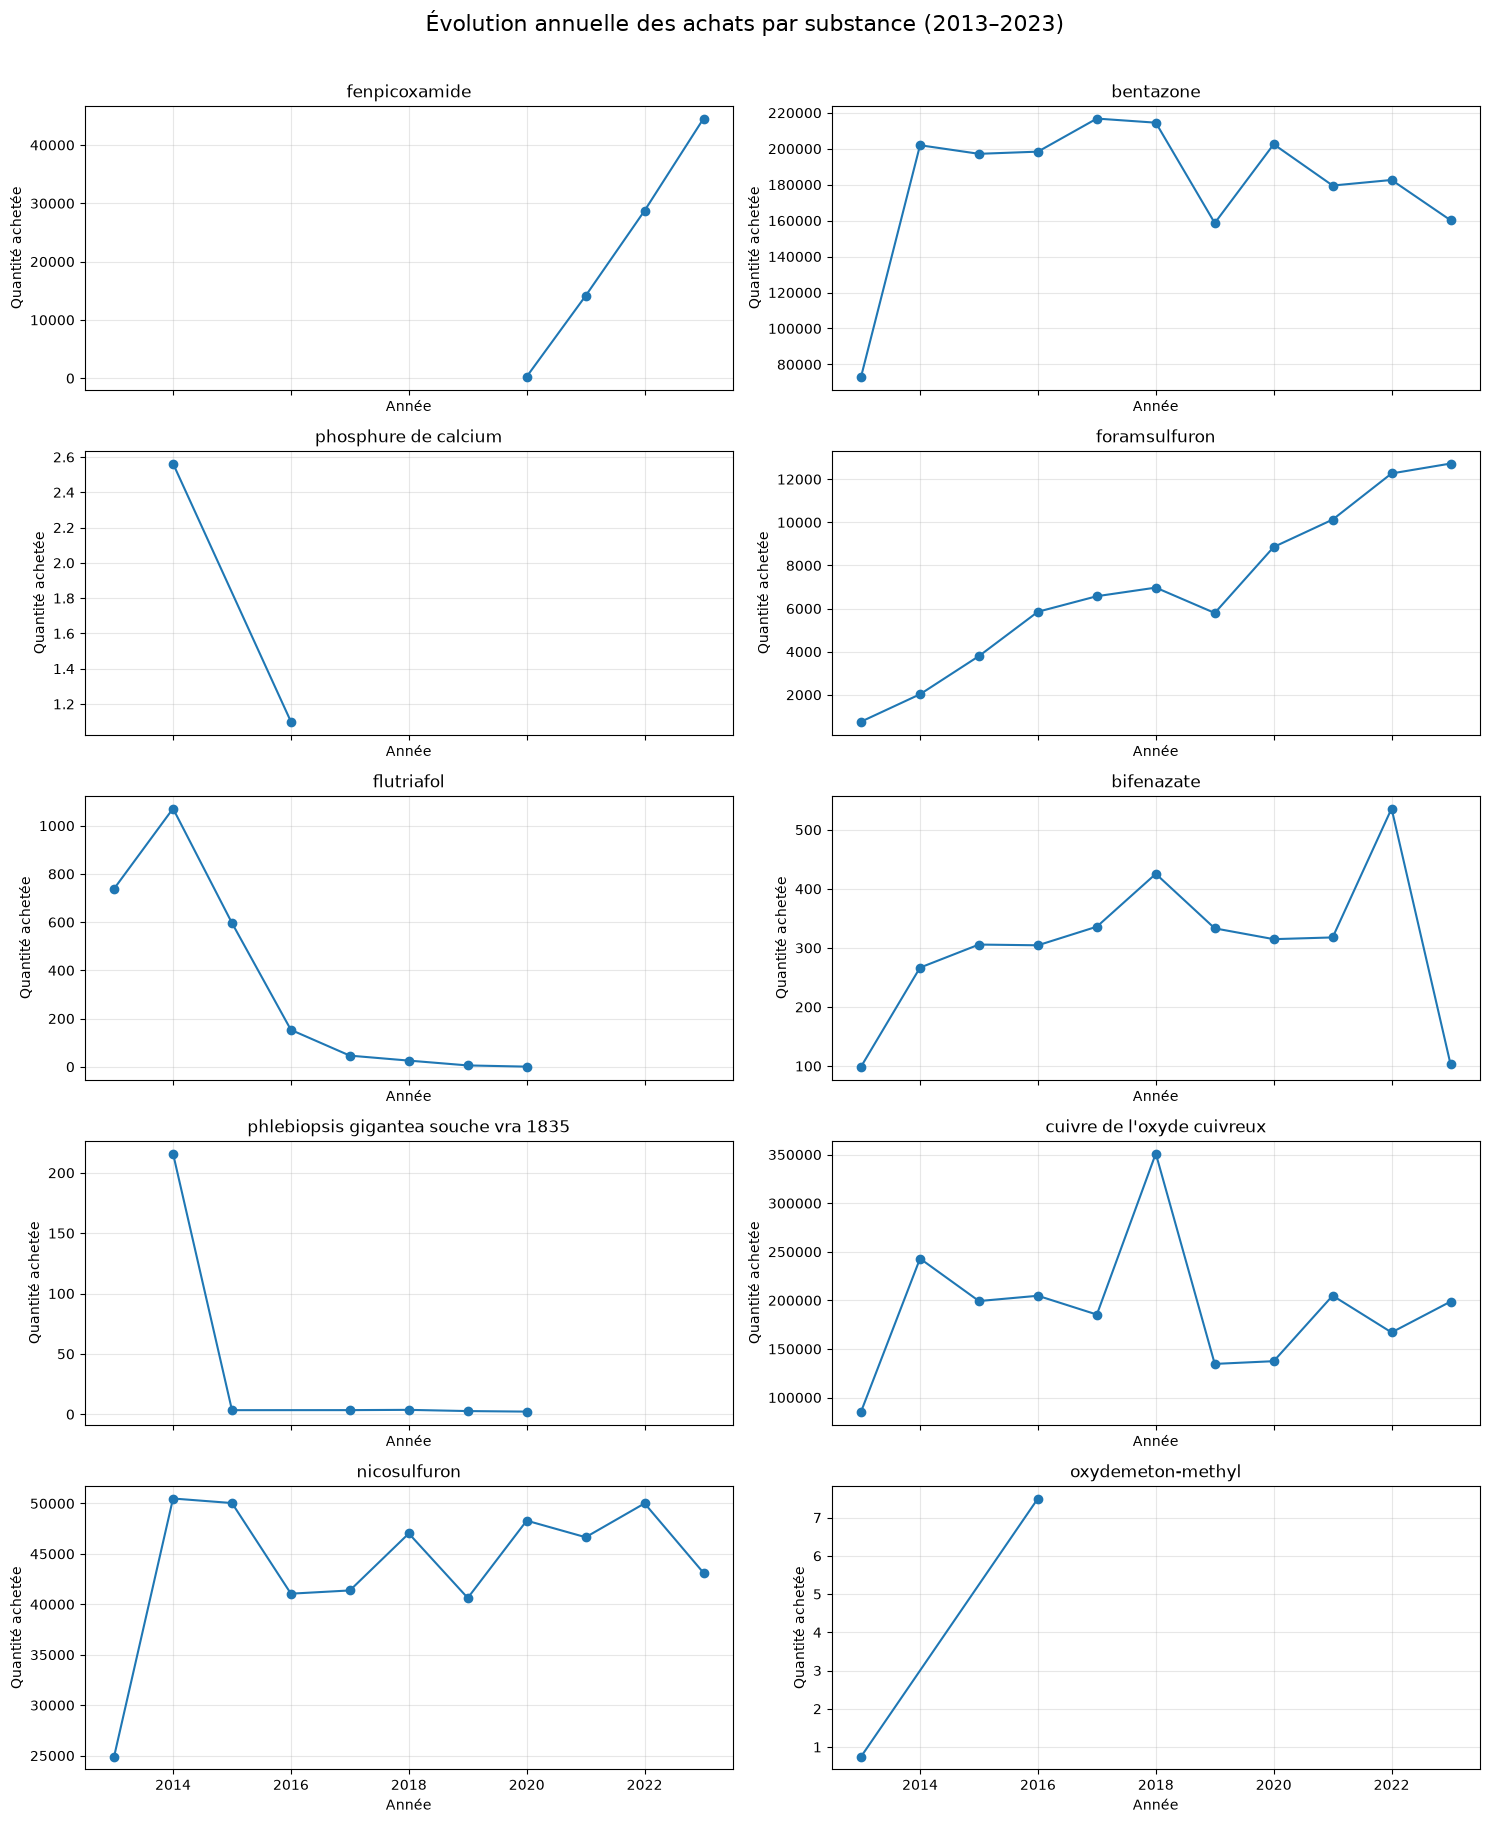

In [61]:
fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(15, 18),
    sharex=True
)

for ax, substance in zip(axes.flat, substances_selectionnees):
    donnees = (
        df_evolution[df_evolution["substance"] == substance]
        .sort_values("annee")
    )

    ax.plot(
        donnees["annee"],
        donnees["quantite_totale"],
        marker="o"
    )

    ax.set_title(substance)
    ax.set_xlabel("Année")
    ax.set_ylabel("Quantité achetée")
    ax.grid(alpha=0.3)

plt.suptitle(
    "Évolution annuelle des achats par substance (2013–2023)",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

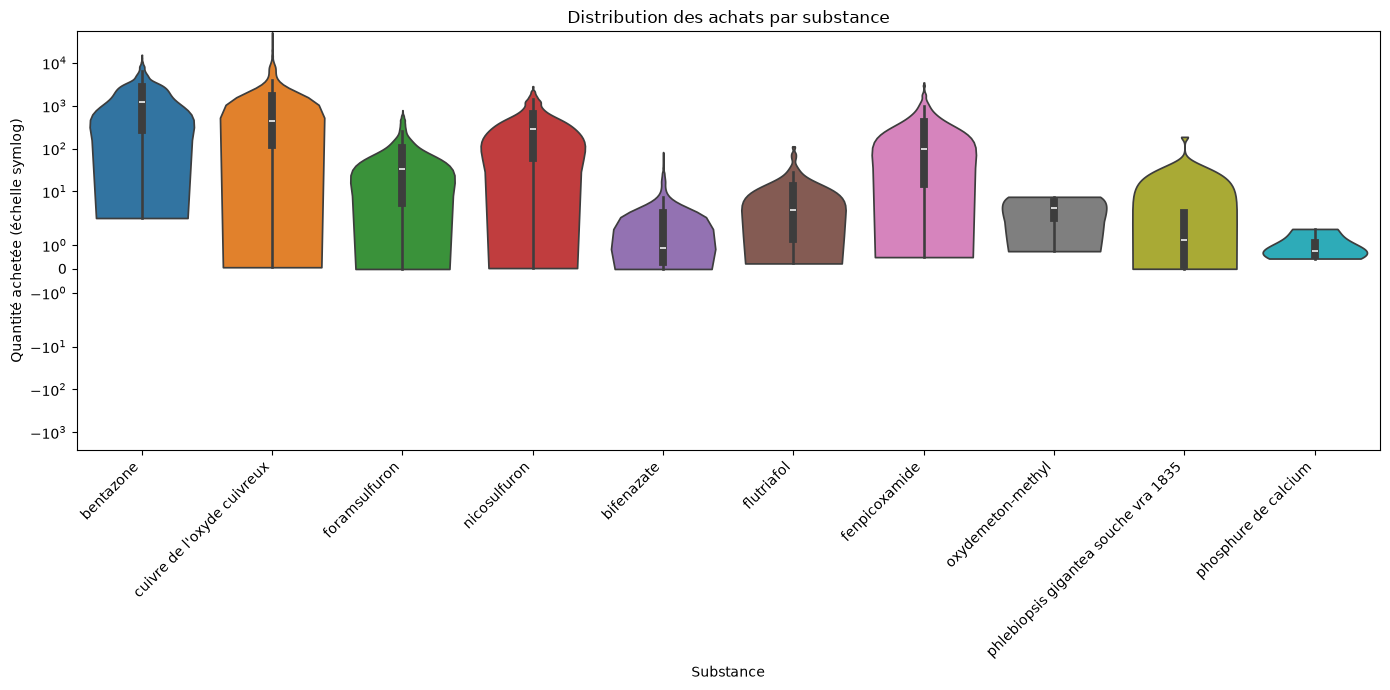

In [62]:
plt.figure(figsize=(14, 7))

sns.violinplot(
    data=df_substances,
    x="substance",
    y="quantite_totale",
    hue="substance",
    legend=False,
    cut=0
)

plt.yscale("symlog")
plt.title("Distribution des achats par substance")
plt.xlabel("Substance")
plt.ylabel("Quantité achetée (échelle symlog)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

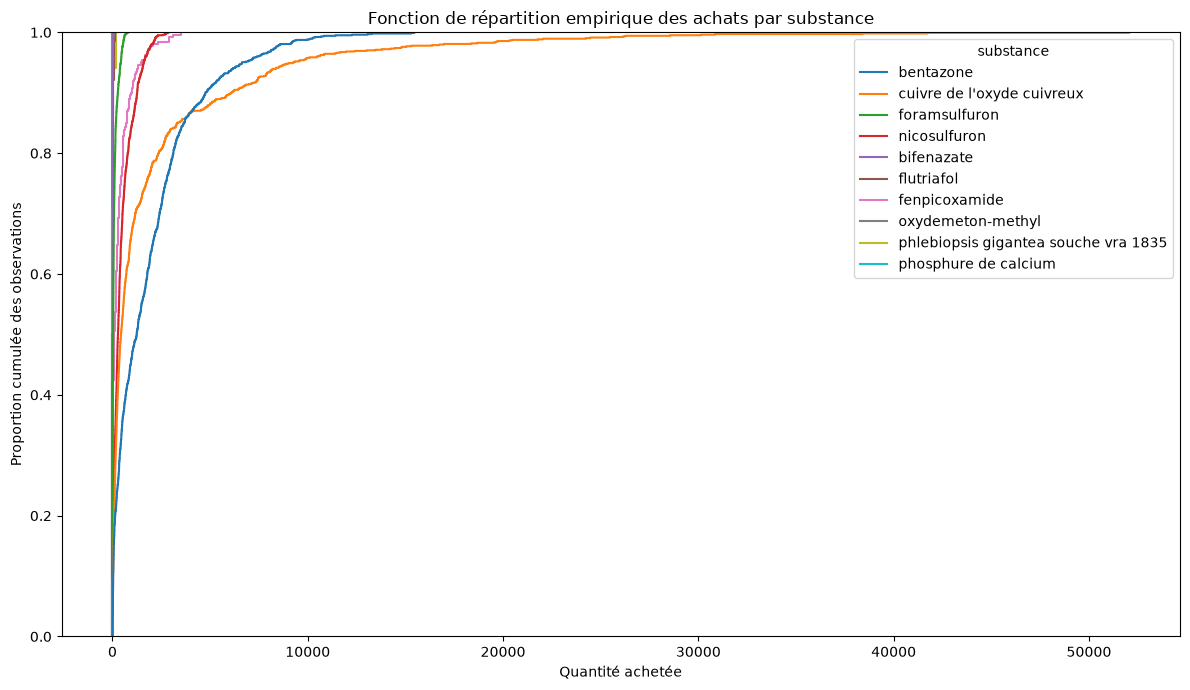

In [64]:
plt.figure(figsize=(12, 7))

sns.ecdfplot(
    data=df_substances,
    x="quantite_totale",
    hue="substance"
)

plt.title("Fonction de répartition empirique des achats par substance")
plt.xlabel("Quantité achetée")
plt.ylabel("Proportion cumulée des observations")
plt.tight_layout()
plt.show()

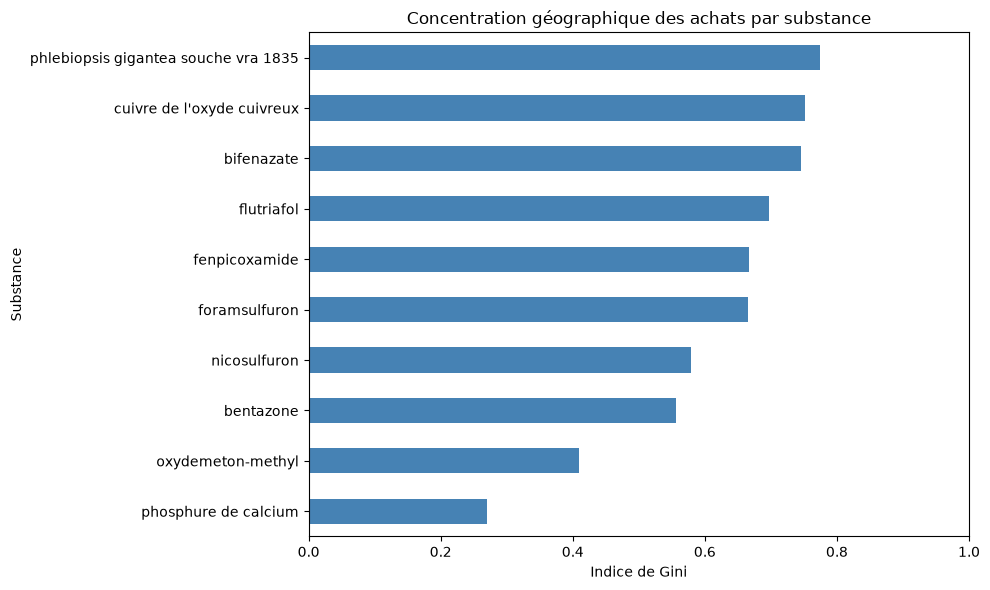

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df_concentration = (
    df_substances
    .groupby(
        ["geocode_departement", "libelle_departement", "substance"],
        as_index=False
    )["quantite_totale"]
    .sum()
)
def calcul_gini(valeurs):
    valeurs = np.asarray(valeurs, dtype=float)

    if np.any(valeurs < 0):
        raise ValueError("Le calcul du Gini nécessite des valeurs positives ou nulles.")

    if valeurs.sum() == 0:
        return np.nan

    valeurs = np.sort(valeurs)
    n = len(valeurs)

    rangs = np.arange(1, n + 1)

    return (2 * np.sum(rangs * valeurs)) / (n * valeurs.sum()) - (n + 1) / n


indices_gini = (
    df_concentration
    .groupby("substance")["quantite_totale"]
    .apply(calcul_gini)
    .sort_values(ascending=False)
)

indices_gini
plt.figure(figsize=(10, 6))

indices_gini.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Concentration géographique des achats par substance")
plt.xlabel("Indice de Gini")
plt.ylabel("Substance")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()



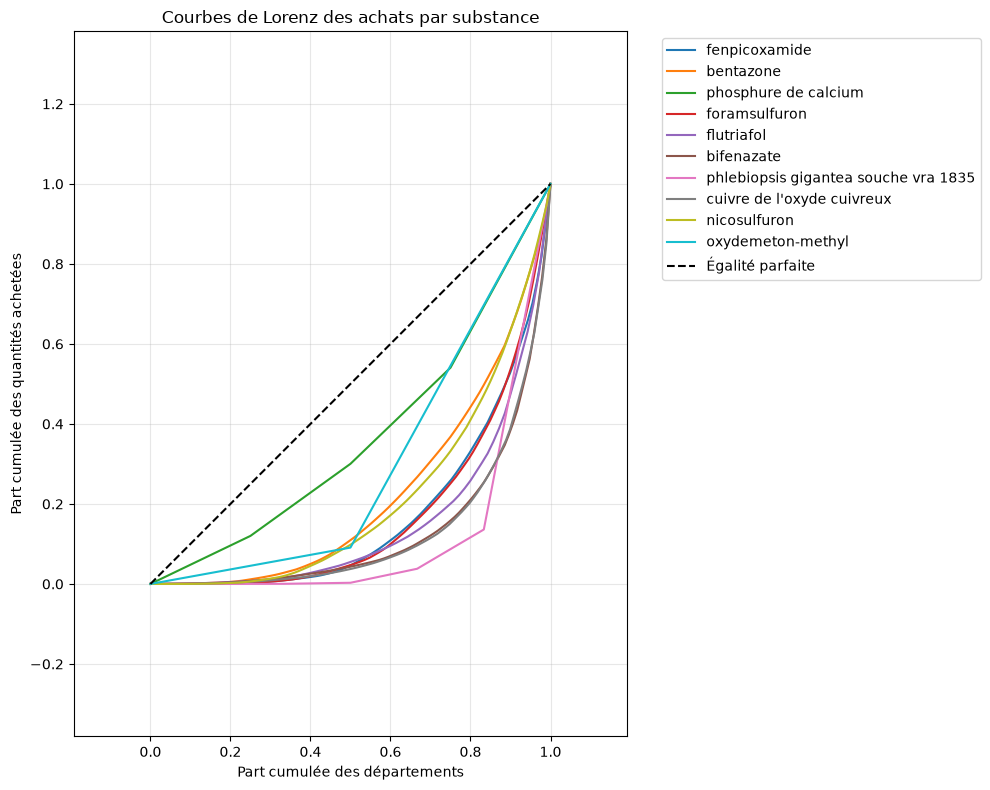

In [73]:
plt.figure(figsize=(10, 8))

for substance in substances_selectionnees:
    quantites = (
        df_concentration[
            df_concentration["substance"] == substance
        ]["quantite_totale"]
        .sort_values()
        .to_numpy()
    )

    if len(quantites) == 0 or quantites.sum() == 0:
        continue

    part_departements = np.arange(len(quantites) + 1) / len(quantites)

    part_quantites = np.insert(
        np.cumsum(quantites) / quantites.sum(),
        0,
        0
    )

    plt.plot(
        part_departements,
        part_quantites,
        label=substance
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="black",
    label="Égalité parfaite"
)

plt.title("Courbes de Lorenz des achats par substance")
plt.xlabel("Part cumulée des départements")
plt.ylabel("Part cumulée des quantités achetées")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.axis("equal")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

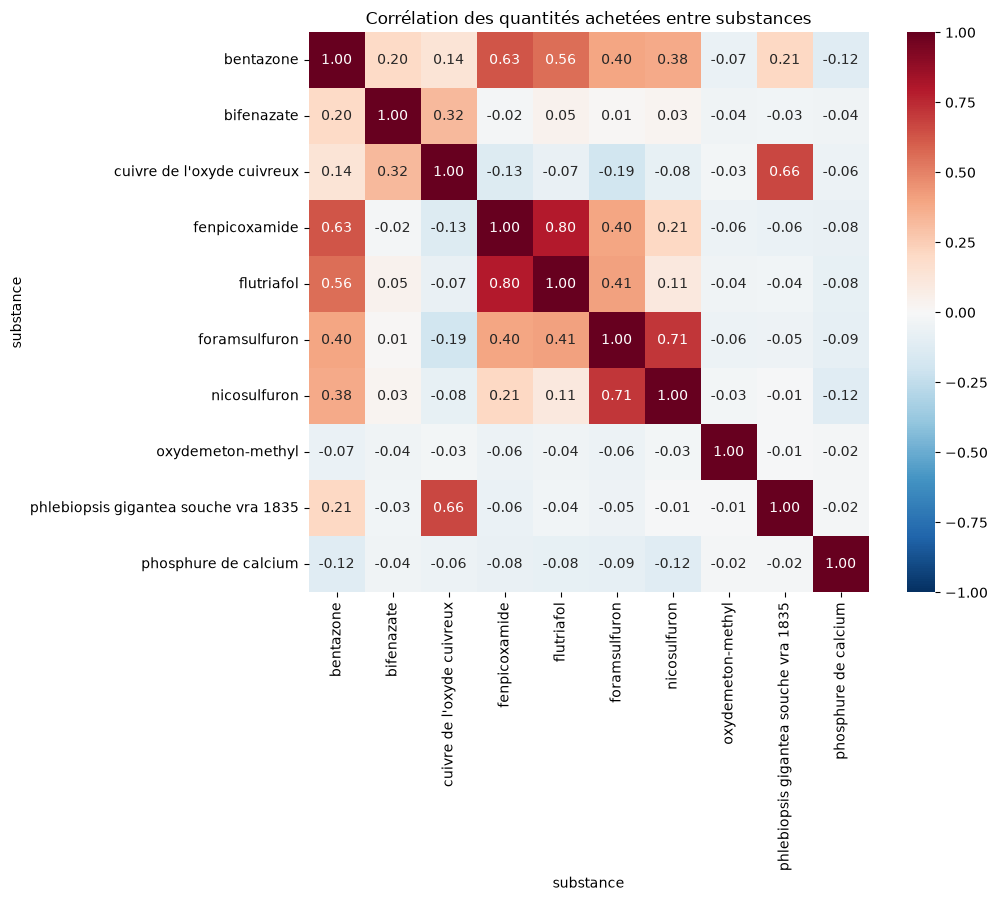

In [74]:
df_correlation = (
    df_concentration
    .pivot(
        index="geocode_departement",
        columns="substance",
        values="quantite_totale"
    )
    .fillna(0)
)

matrice_correlation = df_correlation.corr(method="pearson")

plt.figure(figsize=(11, 9))

sns.heatmap(
    matrice_correlation,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Corrélation des quantités achetées entre substances")
plt.tight_layout()
plt.show()

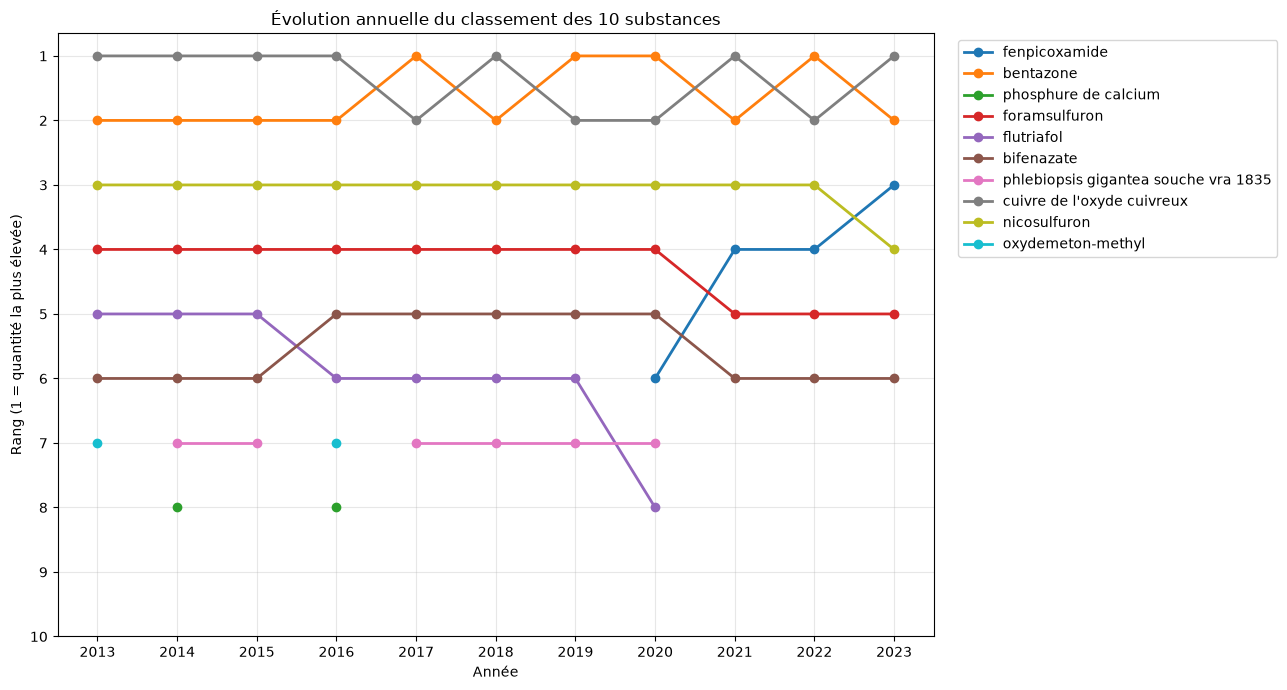

In [76]:
df_classement = df_evolution[
    df_evolution["annee"].isin([2013, 2023])
].copy()

df_classement["rang"] = (
    df_classement
    .groupby("annee")["quantite_totale"]
    .rank(method="min", ascending=False)
)

df_classement.head()


df_classement = df_evolution.copy()

df_classement["rang"] = (
    df_classement
    .groupby("annee")["quantite_totale"]
    .rank(method="min", ascending=False)
)

df_rangs = (
    df_classement
    .pivot(index="annee", columns="substance", values="rang")
    [substances_selectionnees]
)

plt.figure(figsize=(13, 7))

for substance in substances_selectionnees:
    plt.plot(
        df_rangs.index,
        df_rangs[substance],
        marker="o",
        linewidth=2,
        label=substance
    )

plt.gca().invert_yaxis()
plt.xticks(range(2013, 2024))
plt.yticks(range(1, len(substances_selectionnees) + 1))
plt.xlabel("Année")
plt.ylabel("Rang (1 = quantité la plus élevée)")
plt.title("Évolution annuelle du classement des 10 substances")
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

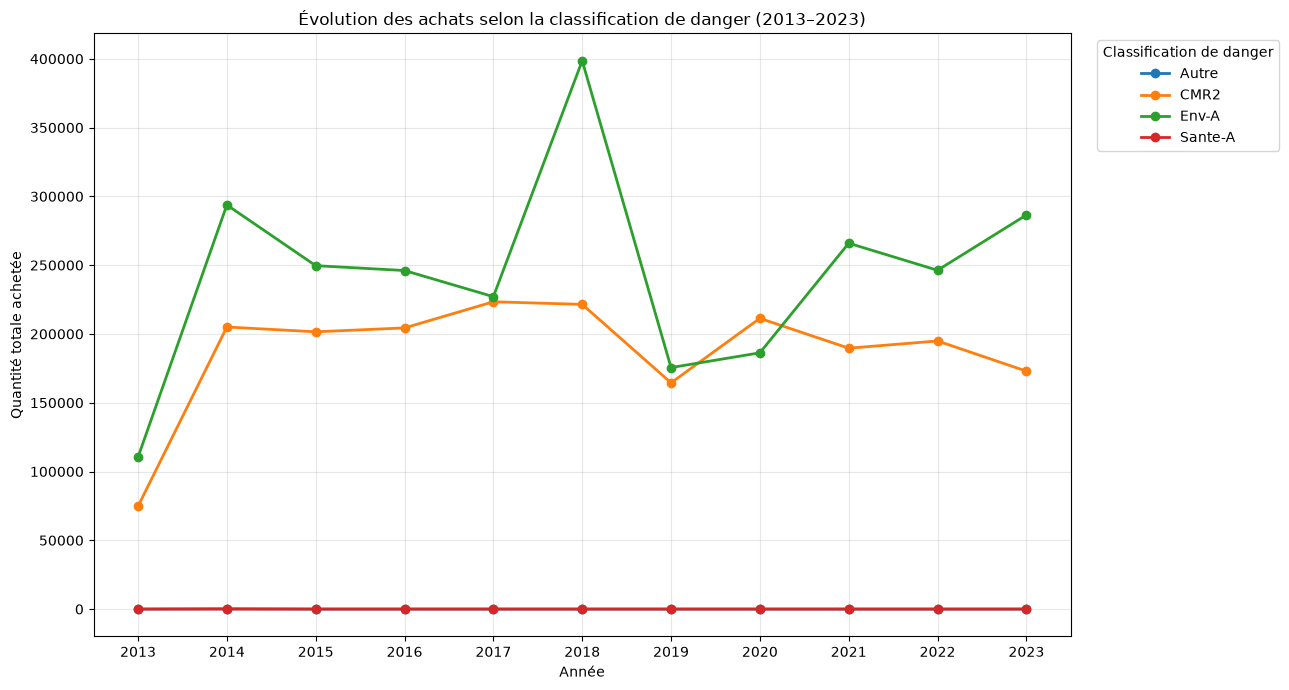

In [77]:
df_danger = (
    df_substances
    .groupby(["annee", "danger_substance"], as_index=False)["quantite_totale"]
    .sum()
)

df_danger_pivot = (
    df_danger
    .pivot(index="annee", columns="danger_substance", values="quantite_totale")
    .fillna(0)
)

df_danger_pivot.plot(
    kind="line",
    marker="o",
    figsize=(13, 7),
    linewidth=2
)

plt.title("Évolution des achats selon la classification de danger (2013–2023)")
plt.xlabel("Année")
plt.ylabel("Quantité totale achetée")
plt.xticks(range(2013, 2024))
plt.legend(title="Classification de danger", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

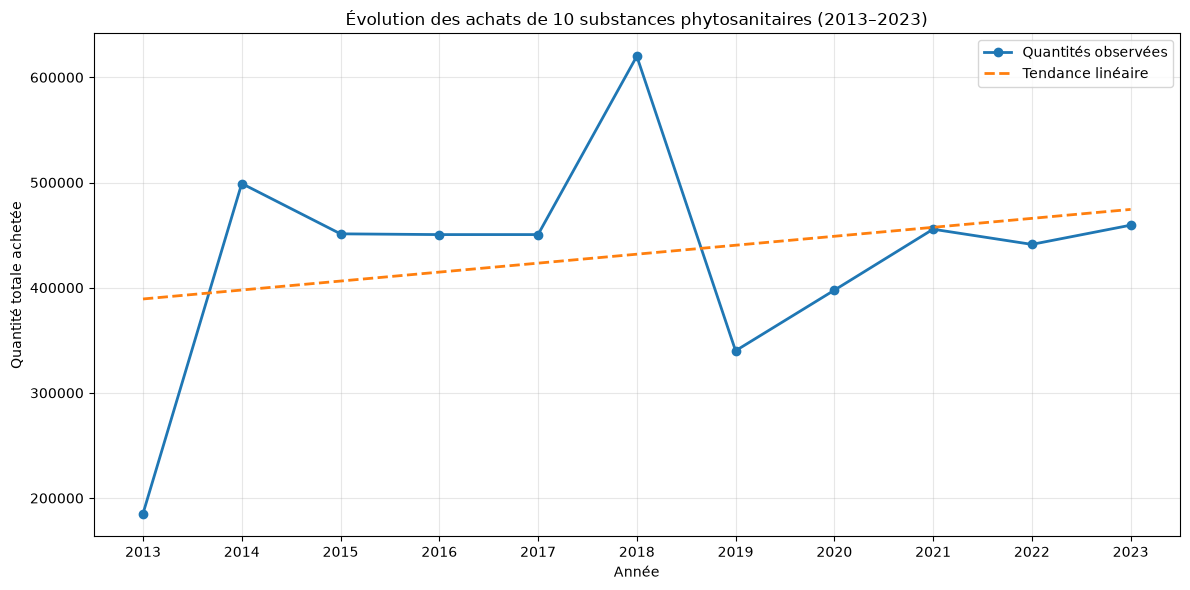

In [78]:
df_tendance = (
    df_evolution
    .groupby("annee", as_index=False)["quantite_totale"]
    .sum()
)

df_tendance


import numpy as np
import matplotlib.pyplot as plt

x = df_tendance["annee"].to_numpy()
y = df_tendance["quantite_totale"].to_numpy()

# Ajustement d'une droite sur l'ensemble de la période
coefficients = np.polyfit(x, y, 1)
tendance = np.polyval(coefficients, x)

plt.figure(figsize=(12, 6))

plt.plot(x, y, marker="o", linewidth=2, label="Quantités observées")
plt.plot(x, tendance, linestyle="--", linewidth=2, label="Tendance linéaire")

plt.xticks(range(2013, 2024))
plt.xlabel("Année")
plt.ylabel("Quantité totale achetée")
plt.title("Évolution des achats de 10 substances phytosanitaires (2013–2023)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [81]:
df_tendance = df_evolution.copy()

df_tendance = df_tendance.sort_values(["substance", "annee"])

df_tendance["variation_absolue"] = (
    df_tendance.groupby("substance")["quantite_totale"].diff()
)

df_tendance["variation_pct"] = (
    df_tendance.groupby("substance")["quantite_totale"].pct_change() * 100
)

df_tendance

,annee,substance,quantite_totale,variation_absolue,variation_pct
0,2013,bentazone,73206.688,NaN,NaN
7,2014,bentazone,201947.696,128741.008,175.859626
15,2015,bentazone,197164.635,-4783.061,-2.368465
22,2016,bentazone,198374.848,1210.213,0.613808
30,2017,bentazone,216771.332,18396.484,9.273597
...,...,...,...,...,...
43,2018,phlebiopsis gigantea souche vra 1835,3.651,0.216,6.288210
50,2019,phlebiopsis gigantea souche vra 1835,2.650,-1.001,-27.417146
58,2020,phlebiopsis gigantea souche vra 1835,2.200,-0.450,-16.981132
14,2014,phosphure de calcium,2.563,NaN,NaN


In [82]:
df_tendance = df_evolution.copy()

df_tendance = df_tendance.sort_values(["substance", "annee"])

df_tendance["variation_absolue"] = (
    df_tendance.groupby("substance")["quantite_totale"].diff()
)

df_tendance["variation_pct"] = (
    df_tendance.groupby("substance")["quantite_totale"].pct_change() * 100
)

df_tendance

,annee,substance,quantite_totale,variation_absolue,variation_pct
0,2013,bentazone,73206.688,NaN,NaN
7,2014,bentazone,201947.696,128741.008,175.859626
15,2015,bentazone,197164.635,-4783.061,-2.368465
22,2016,bentazone,198374.848,1210.213,0.613808
30,2017,bentazone,216771.332,18396.484,9.273597
...,...,...,...,...,...
43,2018,phlebiopsis gigantea souche vra 1835,3.651,0.216,6.288210
50,2019,phlebiopsis gigantea souche vra 1835,2.650,-1.001,-27.417146
58,2020,phlebiopsis gigantea souche vra 1835,2.200,-0.450,-16.981132
14,2014,phosphure de calcium,2.563,NaN,NaN


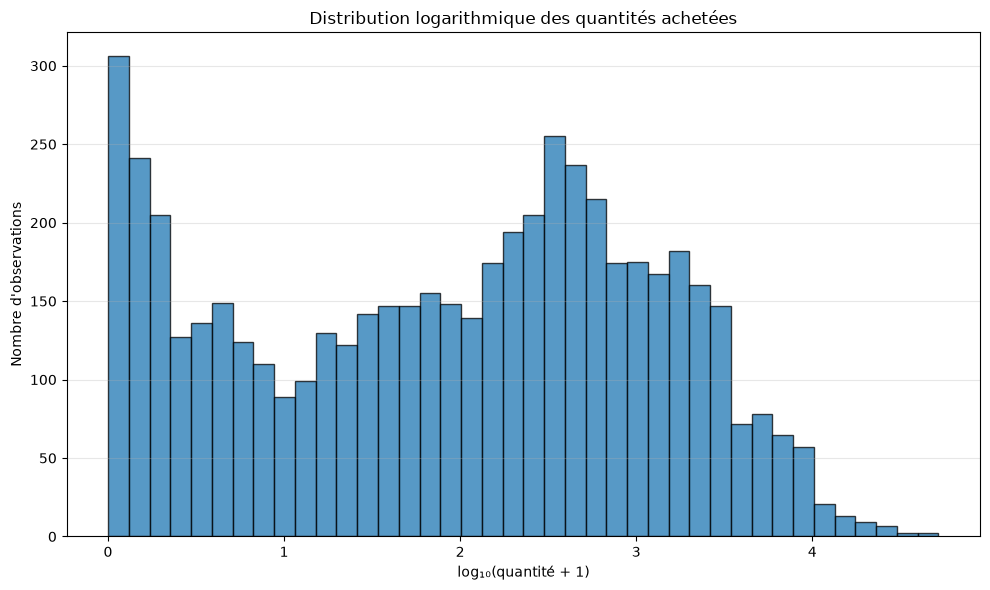

In [84]:
plt.figure(figsize=(10, 6))

plt.hist(
    np.log10(df_substances["quantite_totale"] + 1),
    bins=40,
    edgecolor="black",
    alpha=0.75
)

plt.title("Distribution logarithmique des quantités achetées")
plt.xlabel("log₁₀(quantité + 1)")
plt.ylabel("Nombre d'observations")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

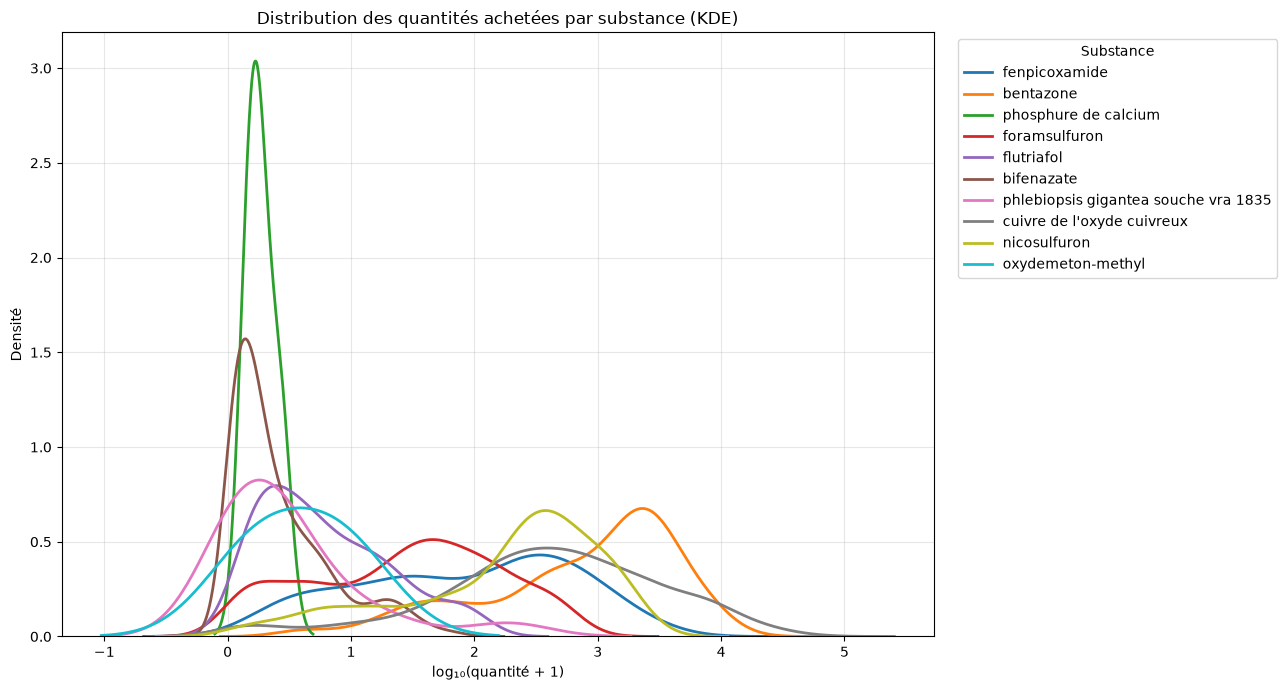

In [86]:
plt.figure(figsize=(13, 7))

for substance in substances_selectionnees:
    valeurs = df_substances.loc[
        df_substances["substance"] == substance,
        "quantite_totale"
    ]

    valeurs_log = np.log10(valeurs + 1)

    sns.kdeplot(
        x=valeurs_log,
        label=substance,
        linewidth=2
    )

plt.title("Distribution des quantités achetées par substance (KDE)")
plt.xlabel("log₁₀(quantité + 1)")
plt.ylabel("Densité")
plt.legend(title="Substance", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()